In [1]:
!mamba install pandas
mamba install scikit-learn
pip install seaborn



mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.558 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.747 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-n

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os
import sys

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

sys.path.append(os.path.abspath("../Src"))

from preprocessing import clean_data, create_preprocessor

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
df = pd.read_csv("../Data/Telco-Customer-Churn.csv")

df = clean_data(df)

print("Dataset Shape:", df.shape)

df.head()


Dataset Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [4]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (5634, 19)
Testing: (1409, 19)


In [5]:
preprocessor = create_preprocessor(X_train)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = np.asarray(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed,
    dtype=np.float32
)

print("Training:", X_train_processed.shape)
print("Testing:", X_test_processed.shape)


Training: (5634, 45)
Testing: (1409, 45)


In [6]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=10,
    random_state=42
)

ann_model.fit(X_train_processed, y_train)

print("ANN Training Completed!")
print("Epochs:", ann_model.n_iter_)


ANN Training Completed!
Epochs: 38


In [7]:
ann_predictions = ann_model.predict(X_test_processed)

ann_probabilities = ann_model.predict_proba(
    X_test_processed
)[:, 1]

print("ANN RESULTS")

print("Accuracy:", accuracy_score(y_test, ann_predictions))
print("Precision:", precision_score(y_test, ann_predictions))
print("Recall:", recall_score(y_test, ann_predictions))
print("F1:", f1_score(y_test, ann_predictions))
print("ROC-AUC:", roc_auc_score(y_test, ann_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, ann_predictions))


ANN RESULTS
Accuracy: 0.7899219304471257
Precision: 0.625
Recall: 0.5213903743315508
F1: 0.5685131195335277
ROC-AUC: 0.8381125836368803

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.62      0.52      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



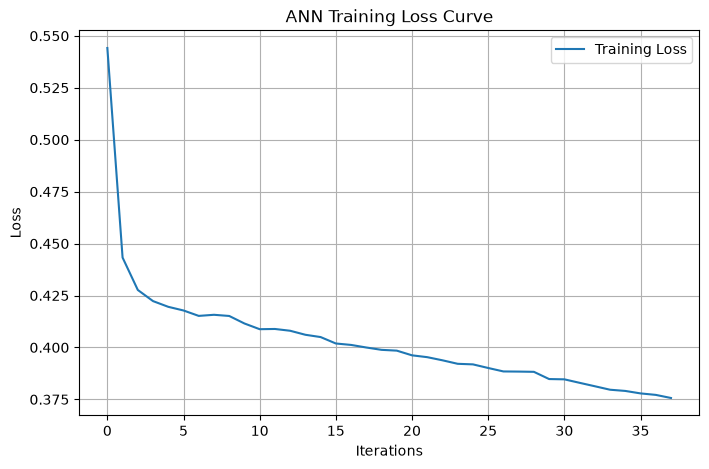

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(ann_model.loss_curve_, label="Training Loss")

plt.title("ANN Training Loss Curve")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


In [9]:
comparison_day5 = pd.DataFrame({
    "Model": [
        "Day 3 Champion",
        "Day 4 Random Forest",
        "Day 4 Boosting",
        "Day 5 ANN"
    ],
    "Accuracy": [
        0.8012,
        0.7999,
        0.7984,
        accuracy_score(y_test, ann_predictions)
    ],
    "Precision": [
        0.6459,
        0.6513,
        0.6541,
        precision_score(y_test, ann_predictions)
    ],
    "Recall": [
        0.5546,
        0.5294,
        0.5107,
        recall_score(y_test, ann_predictions)
    ],
    "ROC-AUC": [
        0.8296,
        0.8351,
        0.8357,
        roc_auc_score(y_test, ann_probabilities)
    ]
})

comparison_day5


,Model,Accuracy,Precision,Recall,ROC-AUC
0,Day 3 Champion,0.801200,0.6459,0.55460,0.829600
1,Day 4 Random Forest,0.799900,0.6513,0.52940,0.835100
2,Day 4 Boosting,0.798400,0.6541,0.51070,0.835700
3,Day 5 ANN,0.789922,0.6250,0.52139,0.838113


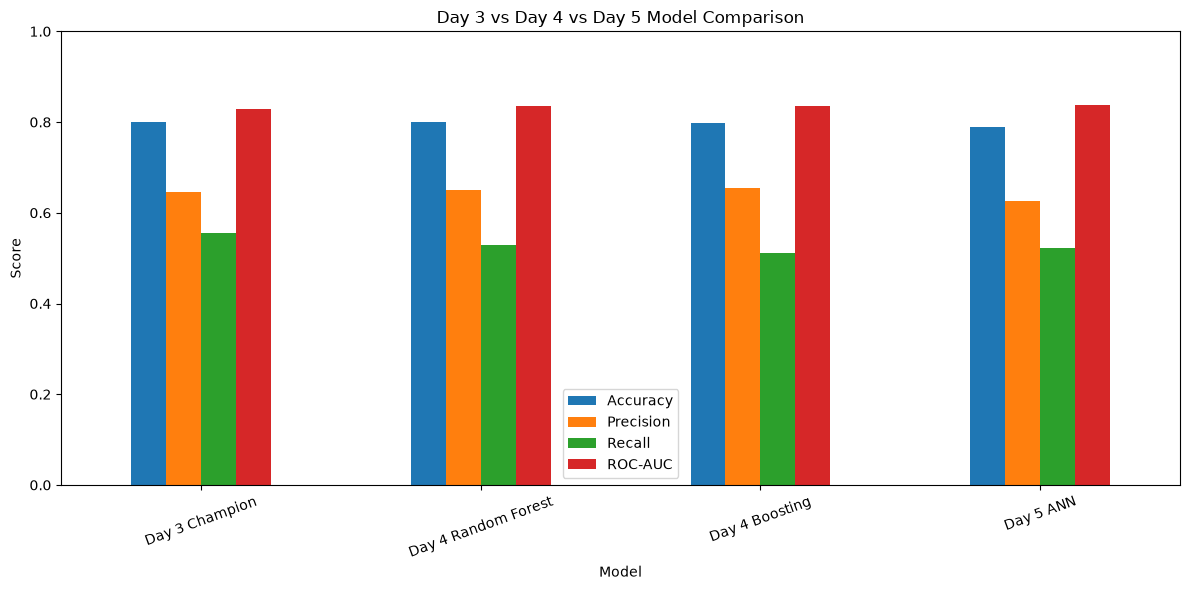

In [10]:
comparison_day5.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Day 3 vs Day 4 vs Day 5 Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [11]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
    ann_model,
    "../models/day5_ann_model.joblib"
)

joblib.dump(
    preprocessor,
    "../models/day5_preprocessor.joblib"
)

print("Day 5 ANN model saved successfully!")


Day 5 ANN model saved successfully!


In [12]:
print(os.listdir("../models"))


['champion_churn_pipeline.joblib', 'churn_pipeline.joblib', 'churn_v3.joblib', 'day2_champion_model.joblib', 'day4_boosting_pipeline.joblib', 'day4_feature_selector.joblib', 'day4_hist_gradient_boosting.joblib', 'day4_preprocessor.joblib', 'day4_random_forest.joblib', 'day4_random_forest_pipeline.joblib', 'day5_ann_model.joblib', 'day5_preprocessor.joblib', 'final_churn_model.joblib']


In [13]:
best_model = comparison_day5.loc[
    comparison_day5["ROC-AUC"].idxmax()
]

print("BEST MODEL:", best_model["Model"])
print("ROC-AUC:", best_model["ROC-AUC"])
print("\nDAY 5 COMPLETED!")


BEST MODEL: Day 5 ANN
ROC-AUC: 0.8381125836368803

DAY 5 COMPLETED!
